# Finding 1 · Google review volume and restaurant closure

**Question.** How does Google review volume relate to whether a Chicago restaurant was marked permanently closed, and how does the association change after accounting for observed age, restaurant characteristics, and community area?

**Starting result.** Our EDA found 52.0% marked permanently closed in the lowest review-count quartile versus 7.0% in the highest. A restaurant that stays open can accumulate reviews for longer, so this raw comparison mixes review activity with how long a business has been around.

Run from the repository root or the notebook directory with Python 3.10+ and pandas, numpy, scipy, statsmodels, and matplotlib. The Google archives belong in the repository's data directory. The notebook caches the City license extract and a small review summary there and reproduces the figure and model table when rerun.

**Sources.** [Google Local Data (2021)](https://jiachengli1995.github.io/google/index.html) covers reviews through September 2021. [Chicago Business Licenses](https://data.cityofchicago.org/d/r5kz-chrr) includes license history, names, addresses, and community area. The [EDA notebook](../EDA_Checkpoint/eda.ipynb) defines the original Chicago restaurant cohort and outcome.

In [1]:
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from difflib import SequenceMatcher
from io import BytesIO
from pathlib import Path
import gzip
import json
import re
import time
import unicodedata
from urllib.error import URLError
from urllib.parse import urlencode
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from scipy.spatial import cKDTree
from scipy.special import expit
import statsmodels.api as sm
from statsmodels.stats.proportion import proportion_confint

repo = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "EDA_Checkpoint/eda.ipynb").is_file()),
    None,
)
if repo is None:
    raise FileNotFoundError("Open this notebook inside the project repository.")
data_dir = repo / "data"
cache_dir = data_dir / "finding_1"
cache_dir.mkdir(exist_ok=True)
cutoff = pd.Timestamp("2021-09-30")
cutoff_exclusive = cutoff + pd.Timedelta(days=1)

## Reproduce the exploratory comparison

Use the EDA filters for Chicago addresses, Google restaurant categories, and unique Google business IDs. The outcome is 1 for permanently closed and 0 for observed operating. Exclude temporary closures and missing status from the model. Keep those records in the coverage audit.

The metadata count defines review volume. Report the original quartiles with Wilson intervals for each rate and a Newcombe interval for the difference.

In [2]:
metadata_columns = [
    "gmap_id", "name", "address", "category", "state", "latitude", "longitude",
    "num_of_reviews", "avg_rating",
]
metadata = pd.read_json(data_dir / "meta-Illinois.json.gz", lines=True)[metadata_columns]
is_restaurant = metadata["category"].map(
    lambda values: isinstance(values, list) and any("restaurant" in str(v).lower() for v in values)
)
is_chicago = metadata["address"].str.contains(r",\s*Chicago,\s*IL\b", case=False, na=False)
restaurants = metadata.loc[is_restaurant & is_chicago].drop_duplicates("gmap_id").copy()

status = restaurants["state"].fillna("").str.strip().str.casefold()
restaurants["status_group"] = np.select(
    [status.eq("permanently closed"), status.str.contains("temporarily closed"), status.eq("")],
    ["Permanently closed", "Temporarily closed", "Missing status"],
    default="Observed operating",
)
known = restaurants["status_group"].isin(["Observed operating", "Permanently closed"])
restaurants["permanently_closed"] = restaurants["status_group"].map(
    {"Observed operating": 0, "Permanently closed": 1}
)
analysis = restaurants.loc[known].copy()
assert restaurants["gmap_id"].is_unique
assert analysis["num_of_reviews"].gt(0).all() and analysis["avg_rating"].between(1, 5).all()
assert analysis["permanently_closed"].nunique() == 2

quartile_labels = ["Q1", "Q2", "Q3", "Q4"]
analysis["quartile"], quartile_edges = pd.qcut(
    analysis["num_of_reviews"], 4, labels=quartile_labels, retbins=True
)
quartiles = analysis.groupby("quartile", observed=True).agg(
    locations=("gmap_id", "size"),
    closed=("permanently_closed", "sum"),
    min_reviews=("num_of_reviews", "min"),
    median_reviews=("num_of_reviews", "median"),
    max_reviews=("num_of_reviews", "max"),
)
quartiles["rate"] = quartiles["closed"] / quartiles["locations"]
quartiles["lower"], quartiles["upper"] = proportion_confint(
    quartiles["closed"], quartiles["locations"], method="wilson"
)
low_row, high_row = quartiles.loc["Q1"], quartiles.loc["Q4"]
gap = low_row["rate"] - high_row["rate"]
gap_lower = gap - np.hypot(low_row["rate"] - low_row["lower"], high_row["upper"] - high_row["rate"])
gap_upper = gap + np.hypot(low_row["upper"] - low_row["rate"], high_row["rate"] - high_row["lower"])

display(restaurants["status_group"].value_counts().to_frame("locations"))
display(quartiles.assign(**{
    key: quartiles[key].map("{:.1%}".format) for key in ["rate", "lower", "upper"]
}))
print(f"Raw Q1 minus Q4 gap: {100 * gap:.1f} pp (95% CI {100 * gap_lower:.1f} to {100 * gap_upper:.1f})")

,locations
status_group,
Observed operating,3989
Missing status,2313
Permanently closed,1440
Temporarily closed,292


,locations,closed,min_reviews,median_reviews,max_reviews,rate,lower,upper
quartile,,,,,,,,
Q1,1376,716.0,1,18.0,46,52.0%,49.4%,54.7%
Q2,1339,416.0,47,77.0,119,31.1%,28.6%,33.6%
Q3,1394,216.0,121,192.5,298,15.5%,13.7%,17.5%
Q4,1320,92.0,302,518.0,9998,7.0%,5.7%,8.5%


Raw Q1 minus Q4 gap: 45.1 pp (95% CI 42.0 to 48.0)


## Link licenses to Google locations

Retrieve all Retail Food Establishment license records with an issue date through September 30, 2021. Use a normalized street address to find candidates and compare names against both the doing-business-as name and legal name. Accept an exact normalized name or a name similarity of at least 0.90 with a lead of at least 0.08 over the next candidate. If the top two accounts tie or nearly tie, leave the location unmatched. Reject matches whose available coordinates are over 150 m apart. Keep the earliest issue date and use the community area when the records for the selected account and site agree.

Age is the number of years from the earliest matched food-license issue date to the common September 2021 reference date. License coverage begins in 2002. Renewals, ownership changes, and gaps in the City data can shorten the observed history, and the proxy does not measure years in operation up to closure.

In [3]:
license_columns = [
    "id", "account_number", "site_number", "legal_name", "doing_business_as_name",
    "address", "community_area", "date_issued", "latitude", "longitude",
]
license_endpoint = "https://data.cityofchicago.org/resource/r5kz-chrr.json"
license_filter = (
    "license_description = 'Retail Food Establishment' AND "
    f"date_issued < '{cutoff_exclusive:%Y-%m-%d}T00:00:00'"
)

def city_query(parameters):
    url = license_endpoint + "?" + urlencode(parameters)
    for attempt in range(3):
        try:
            with urlopen(url, timeout=90) as response:
                return json.load(response)
        except (URLError, TimeoutError):
            if attempt == 2:
                raise
            time.sleep(2 ** attempt)

license_cache = cache_dir / "retail_food_licenses_through_2021_09.json.gz"
if license_cache.exists():
    with gzip.open(license_cache, "rt", encoding="utf-8") as file:
        license_extract = json.load(file)
else:
    expected = int(city_query({"$select": "count(*)", "$where": license_filter})[0]["count"])
    page_size = 25000

    def fetch_page(offset):
        return city_query({
            "$select": ",".join(license_columns + [":id as source_row_id"]),
            "$where": license_filter, "$order": "id,:id", "$limit": page_size, "$offset": offset,
        })

    with ThreadPoolExecutor(max_workers=3) as pool:
        pages = pool.map(fetch_page, range(0, expected, page_size))
        records = [row for page in pages for row in page]
    unique_rows = len({row["source_row_id"] for row in records})
    if len(records) != expected or unique_rows != expected:
        raise RuntimeError(f"Expected {expected} license rows, got {len(records)} ({unique_rows} unique).")
    license_extract = {
        "retrieved_utc": pd.Timestamp.now(tz="UTC").isoformat(),
        "records": records,
    }
    temporary = license_cache.with_suffix(".tmp")
    with gzip.open(temporary, "wt", encoding="utf-8") as file:
        json.dump(license_extract, file)
    temporary.replace(license_cache)

licenses = pd.DataFrame(license_extract["records"]).reindex(columns=license_columns)
print(f"License rows: {len(licenses):,} | Retrieved {license_extract['retrieved_utc'][:10]} UTC")

License rows: 157,942 | Retrieved 2026-11-16 UTC


In [4]:
street_words = {
    "NORTH": "N", "SOUTH": "S", "EAST": "E", "WEST": "W",
    "STREET": "ST", "AVENUE": "AVE", "BOULEVARD": "BLVD", "ROAD": "RD",
    "DRIVE": "DR", "PLACE": "PL", "COURT": "CT", "PARKWAY": "PKWY",
    "LANE": "LN", "TERRACE": "TER", "HIGHWAY": "HWY", "CIRCLE": "CIR",
}
company_suffixes = {"LLC", "INC", "CORP", "CORPORATION", "LTD", "LLP"}

def plain(value):
    if pd.isna(value):
        return ""
    text = unicodedata.normalize("NFKD", str(value)).encode("ascii", "ignore").decode()
    return text.upper()

def street_key(value):
    value = re.split(r",\s*CHICAGO\b", plain(value), maxsplit=1)[0]
    # Google commonly puts the establishment name before the street address.
    segments = re.split(r"\s*,\s*", value)
    value = next((segment for segment in reversed(segments) if re.match(r"^\s*\d+\s+", segment)), "")
    value = re.split(r"#|\b(?:SUITE|STE|UNIT|FLOOR|FL|ROOM|RM|APT)\b", value, maxsplit=1)[0]
    tokens = re.findall(r"[A-Z0-9]+", value)
    tokens = [street_words.get(token, token) for token in tokens]
    if len(tokens) < 3 or not tokens[0].isdigit():
        return ""
    # City records often append floor/room numbers without a label.
    while len(tokens) > 3 and tokens[-1].isdigit():
        tokens.pop()
    return " ".join(tokens)

def name_key(value):
    value = plain(value).replace("'", "").replace("&", " AND ")
    tokens = re.findall(r"[A-Z0-9]+", value)
    while tokens and tokens[-1] in company_suffixes:
        tokens.pop()
    return " ".join(tokens)

def location_distance_m(lat1, lon1, lat2, lon2):
    average_latitude = np.deg2rad((lat1 + lat2) / 2)
    return 111_195 * np.hypot(lat1 - lat2, (lon1 - lon2) * np.cos(average_latitude))

licenses["street_key"] = licenses["address"].map(street_key)
licenses["dba_key"] = licenses["doing_business_as_name"].map(name_key)
licenses["legal_key"] = licenses["legal_name"].map(name_key)
licenses["date_issued"] = pd.to_datetime(licenses["date_issued"], errors="coerce")
licenses["community_area"] = pd.to_numeric(licenses["community_area"], errors="coerce")
licenses["community_area"] = licenses["community_area"].where(licenses["community_area"].between(1, 77))
for column in ["latitude", "longitude"]:
    licenses[column] = pd.to_numeric(licenses[column], errors="coerce")
licenses = licenses.dropna(subset=["account_number", "site_number", "date_issued"])
licenses = licenses.loc[licenses["street_key"].ne("")]

address_index = defaultdict(list)
for (address, account, site), records in licenses.groupby(
    ["street_key", "account_number", "site_number"], sort=False
):
    aliases = set(records["dba_key"]) | set(records["legal_key"])
    areas = records["community_area"].dropna().unique()
    coords = records[["latitude", "longitude"]].dropna()
    coordinates = coords.median() if len(coords) else {"latitude": np.nan, "longitude": np.nan}
    address_index[address].append({
        "account_number": account,
        "site_number": site,
        "aliases": aliases - {""},
        "first_license_issued": records["date_issued"].min(),
        "community_area": int(areas[0]) if len(areas) == 1 else np.nan,
        "latitude": coordinates["latitude"],
        "longitude": coordinates["longitude"],
    })

restaurants["street_key"] = restaurants["address"].map(street_key)
restaurants["name_key"] = restaurants["name"].map(name_key)
links = []
for row in restaurants.itertuples(index=False):
    candidates = []
    for candidate in address_index.get(row.street_key, []):
        if not row.name_key or not candidate["aliases"]:
            continue
        similarity = max(
            SequenceMatcher(None, row.name_key, alias, autojunk=False).ratio()
            for alias in candidate["aliases"]
        )
        distance = location_distance_m(
            row.latitude, row.longitude, candidate["latitude"], candidate["longitude"]
        )
        if np.isfinite(distance) and distance > 150:
            continue
        candidates.append((similarity, distance, candidate))
    candidates.sort(key=lambda match: match[0], reverse=True)
    if not candidates or candidates[0][0] < 0.90:
        continue
    score, distance, candidate = candidates[0]
    if len(candidates) > 1 and score - candidates[1][0] < 0.08:
        continue
    links.append({
        "gmap_id": row.gmap_id,
        "first_license_issued": candidate["first_license_issued"],
        "community_area": candidate["community_area"],
        "name_similarity": score,
        "license_distance_m": distance,
        "license_account": candidate["account_number"],
        "license_site": candidate["site_number"],
    })

license_links = pd.DataFrame(links)
if license_links.empty:
    raise RuntimeError("No restaurant licenses matched. Check the source and the address normalization.")
assert license_links["gmap_id"].is_unique
# Multiple Google listings linked to one City site are ambiguous.
same_city_site = license_links.duplicated(["license_account", "license_site"], keep=False)
print(f"Google listings dropped because they share a matched City site: {same_city_site.sum():,}")
license_links = license_links.loc[~same_city_site].copy()
joined = restaurants.merge(license_links, on="gmap_id", how="left", validate="one_to_one")
joined["license_age_years"] = (cutoff - joined["first_license_issued"]).dt.days / 365.25
assert joined["license_age_years"].dropna().ge(0).all()
joined["has_license_match"] = joined["first_license_issued"].notna()
joined["has_license_area"] = joined["community_area"].notna()

link_audit = joined.groupby("status_group").agg(
    locations=("gmap_id", "size"),
    matched=("has_license_match", "sum"),
    with_area=("has_license_area", "sum"),
    median_review_count=("num_of_reviews", "median"),
)
link_audit["match_rate"] = link_audit["matched"] / link_audit["locations"]
display(link_audit.assign(match_rate=link_audit["match_rate"].map("{:.1%}".format)))
print(f"Exact names among retained links: {license_links['name_similarity'].eq(1).mean():.1%}")
print(f"Median distance among retained links with coordinates: {license_links['license_distance_m'].median():.0f} m")

Google listings dropped because they share a matched City site: 20


,locations,matched,with_area,median_review_count,match_rate
status_group,,,,,
Missing status,2313,584,581,358.0,25.2%
Observed operating,3989,1000,994,168.0,25.1%
Permanently closed,1440,305,302,47.0,21.2%
Temporarily closed,292,48,47,96.5,16.4%


Exact names among retained links: 89.3%
Median distance among retained links with coordinates: 14 m


## Construct the other predictors

Use mean stars and the percentage of archived Google ratings at 1 or 2 stars. The archive rating total can differ from the review count reported in the metadata. Keep each as its own measure. Use the first restaurant category listed on Google and pool sparse categories before modeling. A chain proxy flags the same normalized name at multiple Chicago addresses. Competition is the number of other Google restaurant listings within 500 m using coordinates, including listings with unknown status. This measures local restaurant density in the archive.

Use the first dated Google review to form a second age proxy for sensitivity analysis, with the same September 2021 reference date for all locations.

In [5]:
review_archive = data_dir / "review-Illinois.json.gz"
review_cache = cache_dir / "google_chicago_review_summary.json.gz"
review_ids = set(restaurants["gmap_id"])
review_cache_key = {
    "file_bytes": review_archive.stat().st_size,
    "ids": sorted(review_ids),
    "cutoff_exclusive": cutoff_exclusive.isoformat(),
    "version": 1,
}
review_extract = {}
if review_cache.exists():
    with gzip.open(review_cache, "rt", encoding="utf-8") as file:
        review_extract = json.load(file)
if review_extract.get("key") != review_cache_key:
    cutoff_ms = int(cutoff_exclusive.tz_localize("UTC").timestamp() * 1000)
    summary = {}
    with gzip.open(review_archive, "rb") as archive:
        for line in archive:
            review = json.loads(line)
            business_id = review.get("gmap_id")
            when = review.get("time")
            rating = review.get("rating")
            if business_id not in review_ids or not isinstance(when, (int, float)):
                continue
            if not 0 < when < cutoff_ms or rating not in (1, 2, 3, 4, 5):
                continue
            counts = summary.setdefault(business_id, [0, 0, when])
            counts[0] += 1
            counts[1] += rating <= 2
            counts[2] = min(counts[2], when)
    review_extract = {"key": review_cache_key, "summary": summary}
    temporary = review_cache.with_suffix(".tmp")
    with gzip.open(temporary, "wt", encoding="utf-8") as file:
        json.dump(review_extract, file)
    temporary.replace(review_cache)

review_features = pd.DataFrame.from_dict(
    review_extract["summary"], orient="index",
    columns=["archived_rating_count", "negative_rating_count", "first_review_ms"],
).rename_axis("gmap_id").reset_index()
review_features["negative_share"] = (
    review_features["negative_rating_count"] / review_features["archived_rating_count"]
)
review_features["first_google_review"] = pd.to_datetime(review_features.pop("first_review_ms"), unit="ms")
review_features["review_age_years"] = (
    (cutoff_exclusive - review_features["first_google_review"]).dt.total_seconds()
    / (365.25 * 86400)
)
print(f"Restaurants with dated archive ratings: {len(review_features):,} / {len(restaurants):,}")

Restaurants with dated archive ratings: 8,034 / 8,034


In [6]:
joined = joined.merge(review_features, on="gmap_id", how="left", validate="one_to_one")
joined["category"] = joined["category"].map(
    lambda values: next(value for value in values if "restaurant" in value.lower())
)
valid_street = joined["name_key"].ne("") & joined["street_key"].ne("")
location_counts = joined.loc[valid_street].groupby("name_key")["street_key"].nunique()
joined["chain_proxy"] = joined["name_key"].map(location_counts).ge(2).astype(int)

coordinates = joined[["latitude", "longitude"]].apply(pd.to_numeric, errors="coerce")
has_coordinates = coordinates["latitude"].between(41.6, 42.1) & coordinates["longitude"].between(-88, -87.4)
lat, lon = np.deg2rad(coordinates.loc[has_coordinates].to_numpy().T)
sphere_xyz = np.column_stack([np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)])
radius_m = 6_371_000
chord = 2 * np.sin(500 / (2 * radius_m))
n_neighbors = cKDTree(sphere_xyz).query_ball_point(sphere_xyz, chord, return_length=True) - 1
joined["n_competitors_500m"] = np.nan
joined.loc[has_coordinates, "n_competitors_500m"] = n_neighbors
joined["log2_reviews"] = np.log2(joined["num_of_reviews"].where(joined["num_of_reviews"].gt(0)))
joined["log_license_age"] = np.log1p(joined["license_age_years"])
joined["log_review_age"] = np.log1p(joined["review_age_years"])
joined["quartile"] = joined["gmap_id"].map(analysis.set_index("gmap_id")["quartile"])

## Fit four models on the same cohort

Require known Google status, a matched license and community area, and usable values for all predictors. Community areas with only one outcome in the complete records cannot support a within-area comparison, so omit them from all four fits. Use a binomial generalized linear model with a logit link and standard errors clustered by community area. Review count is on a log base 2 scale, making the odds ratio interpretable per doubling of reviews. Use log(1 + years) for the age proxies.

Compare the average fitted probabilities at the original Q1 and Q4 median review counts, assigning the same hypothetical counts to each restaurant while retaining its observed controls. For the probability gap, the delta method uses both estimates and their shared covariance. These are association estimates in the matched cohort.

In [7]:
all_known = joined.loc[joined["permanently_closed"].notna()].copy()
required = [
    "log2_reviews", "log_license_age", "avg_rating", "negative_share", "category",
    "chain_proxy", "n_competitors_500m", "community_area",
]
complete = all_known.dropna(subset=required).copy()
outcomes_by_area = complete.groupby("community_area")["permanently_closed"].nunique()
usable_areas = outcomes_by_area.index[outcomes_by_area.eq(2)]
common = complete.loc[complete["community_area"].isin(usable_areas)].copy()
assert common["gmap_id"].is_unique and common["permanently_closed"].nunique() == 2
assert common["community_area"].nunique() > 1

category_counts = common.groupby("category")["permanently_closed"].agg(["size", "sum"])
common_categories = category_counts.index[
    category_counts["size"].ge(30) & category_counts["sum"].between(3, category_counts["size"] - 3)
]
common["category_group"] = common["category"].where(
    common["category"].isin(common_categories), "Other restaurant categories"
)
common["community_area"] = common["community_area"].astype(int)
funnel = pd.DataFrame([
    ("Known Google status", len(all_known), all_known["permanently_closed"].mean()),
    ("Matched food license", int(all_known["has_license_match"].sum()),
     all_known.loc[all_known["has_license_match"], "permanently_closed"].mean()),
    ("Complete model fields", len(complete), complete["permanently_closed"].mean()),
    ("Common sample with both outcomes represented per area", len(common), common["permanently_closed"].mean()),
], columns=["Cohort", "Restaurants", "Marked closed"])
display(funnel.assign(**{"Marked closed": funnel["Marked closed"].map("{:.1%}".format)}))
print(f"Community areas retained: {common['community_area'].nunique()}")
print(f"Locations omitted from single-outcome areas: {len(complete) - len(common)}")

,Cohort,Restaurants,Marked closed
0,Known Google status,5429,26.5%
1,Matched food license,1305,23.4%
2,Complete model fields,1296,23.3%
3,Common sample with both outcomes represented p...,1164,25.9%


Community areas retained: 51
Locations omitted from single-outcome areas: 132


In [8]:
low_count = float(low_row["median_reviews"])
high_count = float(high_row["median_reviews"])

specs = [
    ("1 · Review count", ["log2_reviews"], []),
    ("2 · Add license age", ["log2_reviews", "log_license_age"], []),
    (
        "3 · Add restaurant controls",
        ["log2_reviews", "log_license_age", "avg_rating", "negative_share",
         "chain_proxy", "n_competitors_500m"],
        ["category_group"],
    ),
    (
        "4 · Add community area",
        ["log2_reviews", "log_license_age", "avg_rating", "negative_share",
         "chain_proxy", "n_competitors_500m"],
        ["category_group", "community_area"],
    ),
]

def fit_and_summarize(label, frame, numeric, categorical):
    x = frame[numeric].astype(float)
    for column in categorical:
        encoded = pd.get_dummies(frame[column].astype(str), prefix=column, drop_first=True, dtype=float)
        x = x.join(encoded)
    x = sm.add_constant(x, has_constant="add")
    groups = frame["community_area"] if frame["community_area"].notna().all() else None
    cov = {"cov_type": "HC1"} if groups is None else {
        "cov_type": "cluster", "cov_kwds": {"groups": groups},
    }
    assert len(frame) == len(x) and np.linalg.matrix_rank(x.to_numpy()) == x.shape[1]
    model = sm.GLM(frame["permanently_closed"], x, family=sm.families.Binomial()).fit(**cov)
    if not model.converged or not np.isfinite(model.cov_params().to_numpy()).all():
        raise RuntimeError(f"{label} did not produce a converged fit with finite uncertainty.")

    beta = model.params.to_numpy()
    covariance = model.cov_params().to_numpy()
    x_low = x.assign(log2_reviews=np.log2(low_count)).to_numpy()
    x_high = x.assign(log2_reviews=np.log2(high_count)).to_numpy()
    p_low = expit(x_low @ beta)
    p_high = expit(x_high @ beta)
    gradient = (
        ((p_low * (1 - p_low)) @ x_low - (p_high * (1 - p_high)) @ x_high)
        / len(x)
    )
    contrast = float((p_low - p_high).mean())
    standard_error = np.sqrt(max(0, float(gradient @ covariance @ gradient)))
    odds_ci = np.exp(model.conf_int().loc["log2_reviews"].to_numpy())
    return {
        "Model": label, "N": int(model.nobs),
        "Odds ratio per doubling": np.exp(model.params["log2_reviews"]),
        "OR lower": odds_ci[0], "OR upper": odds_ci[1],
        "Low count (%)": 100 * p_low.mean(), "High count (%)": 100 * p_high.mean(),
        "Gap (pp)": 100 * contrast,
        "Gap lower": 100 * (contrast - 1.96 * standard_error),
        "Gap upper": 100 * (contrast + 1.96 * standard_error),
    }

fit_results = pd.DataFrame([
    fit_and_summarize(label, common, numeric, categorical)
    for label, numeric, categorical in specs
])
assert fit_results["N"].eq(len(common)).all()
display(fit_results.round(3))
print(f"Low and high comparison counts: {low_count:g} and {high_count:g} reviews per restaurant")

,Model,N,Odds ratio per doubling,OR lower,OR upper,Low count (%),High count (%),Gap (pp),Gap lower,Gap upper
0,1 · Review count,1164,0.551,0.499,0.608,57.731,7.070,50.661,44.056,57.267
1,2 · Add license age,1164,0.483,0.425,0.549,63.590,6.079,57.511,50.575,64.447
2,3 · Add restaurant controls,1164,0.446,0.379,0.524,65.369,6.765,58.604,50.264,66.944
3,4 · Add community area,1164,0.424,0.349,0.514,64.671,6.740,57.930,49.684,66.176


Low and high comparison counts: 18 and 518 reviews per restaurant


## Test alternative explanations

**Age of the restaurant.** Refit the full model with time since first dated Google review as the age proxy. Compare on the same records that have both age measures. This addresses the professor's suggestion about review dates within the Google cohort. Review dates measure observed platform activity. The Princeton analysis is a separate replication.

**License coverage.** Compare the baseline on the full known-status cohort and the matched cohort to see how selection changes the original association. Refit the full model using only exact name matches in community areas with both outcomes. Check the rates of unknown status across review-volume groups. Show extreme bounds on the unadjusted gap by assigning missing statuses to closed or operating in whichever way shrinks or enlarges the gap. These bounds leave temporary closures out and use the original quartile cut points.

In [9]:
label, numeric, categorical = specs[-1]
with_review_age = common.dropna(subset=["log_review_age"])
review_age_numeric = ["log_review_age" if item == "log_license_age" else item for item in numeric]
exact = common.loc[common["name_similarity"].eq(1)].copy()
exact_outcomes = exact.groupby("community_area")["permanently_closed"].nunique()
exact = exact.loc[exact["community_area"].isin(exact_outcomes.index[exact_outcomes.eq(2)])]

selection = fit_and_summarize(
    "Baseline on all known Google statuses",
    all_known.assign(community_area=np.nan), ["log2_reviews"], [],
)
sensitivity_rows = [
    selection,
    fit_results.iloc[0].to_dict(),
    fit_and_summarize("License age on the dual-age sample", with_review_age, numeric, categorical),
    fit_and_summarize("First Google review age on the dual-age sample",
                      with_review_age, review_age_numeric, categorical),
    fit_and_summarize("Exact license-name links only", exact, numeric, categorical),
]
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.round(3))

comparison = joined.loc[joined["status_group"].ne("Temporarily closed")].copy()
comparison["quartile"] = pd.cut(
    comparison["num_of_reviews"],
    bins=[-np.inf, *quartile_edges[1:-1], np.inf],
    labels=quartile_labels,
)
comparison["unknown"] = comparison["status_group"].eq("Missing status")
missing_status = comparison.groupby("quartile", observed=True).agg(
    count=("gmap_id", "size"), unknown=("unknown", "sum"), closed=("permanently_closed", "sum"),
)
missing_status["unknown (%)"] = 100 * missing_status["unknown"] / missing_status["count"]
missing_status["minimum closed rate"] = missing_status["closed"] / missing_status["count"]
missing_status["maximum closed rate"] = (
    (missing_status["closed"] + missing_status["unknown"]) / missing_status["count"]
)
lowest_gap = float(
    missing_status.loc["Q1", "minimum closed rate"] - missing_status.loc["Q4", "maximum closed rate"]
)
highest_gap = float(
    missing_status.loc["Q1", "maximum closed rate"] - missing_status.loc["Q4", "minimum closed rate"]
)
display(missing_status.round(3))
print(f"Unadjusted Q1 minus Q4 gap under extreme missing-status assignments: "
      f"{100 * lowest_gap:.1f} to {100 * highest_gap:.1f} pp")

,Model,N,Odds ratio per doubling,OR lower,OR upper,Low count (%),High count (%),Gap (pp),Gap lower,Gap upper
0,Baseline on all known Google statuses,5429,0.617,0.594,0.640,51.002,9.078,41.923,38.921,44.926
1,1 · Review count,1164,0.551,0.499,0.608,57.731,7.070,50.661,44.056,57.267
2,License age on the dual-age sample,1164,0.424,0.349,0.514,64.671,6.740,57.930,49.684,66.176
3,First Google review age on the dual-age sample,1164,0.376,0.303,0.468,68.535,5.927,62.608,54.769,70.447
4,Exact license-name links only,1026,0.416,0.339,0.509,66.412,7.032,59.380,50.702,68.058


,count,unknown,closed,unknown (%),minimum closed rate,maximum closed rate
quartile,,,,,,
Q1,1777,401,716.0,22.566,0.403,0.629
Q2,1566,227,416.0,14.496,0.266,0.411
Q3,1788,394,216.0,22.036,0.121,0.341
Q4,2611,1291,92.0,49.445,0.035,0.530


Unadjusted Q1 minus Q4 gap under extreme missing-status assignments: -12.7 to 59.3 pp


## Figure and narrative

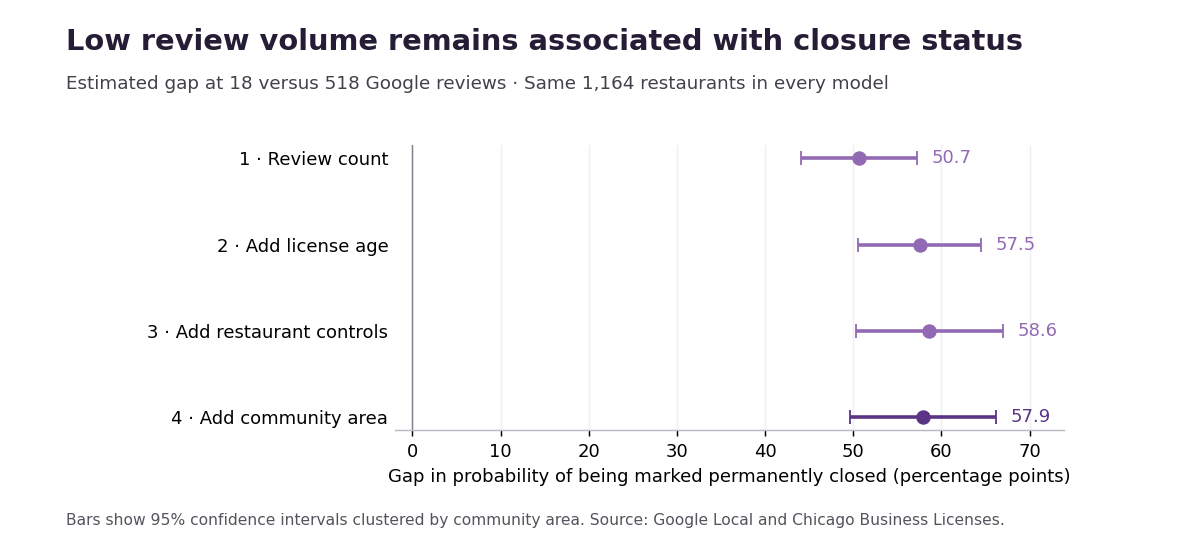

In [10]:
checkpoint_dir = repo / "Checkpoint 5"
figure_path = checkpoint_dir / "finding_1_review_volume_closure.png"
final = fit_results.iloc[-1]
figure_title = (
    "Low review volume remains associated with closure status"
    if final["Gap lower"] > 0
    else "Closure status at low and high review counts after adjustment"
)
fig, ax = plt.subplots(figsize=(9.2, 4.3), dpi=155)
fig.patch.set_facecolor("white")
fig.subplots_adjust(left=0.33, right=0.89, top=0.74, bottom=0.23)
fig.text(0.055, 0.91, figure_title, fontsize=16, fontweight="bold", color="#251D35")
fig.text(
    0.055, 0.84, f"Estimated gap at {low_count:g} versus {high_count:g} Google reviews "
    f"· Same {len(common):,} restaurants in every model", fontsize=10.2, color="#42404A",
)
for i, result in fit_results.iterrows():
    color = "#5B3486" if i == len(fit_results) - 1 else "#926AB3"
    ax.errorbar(
        result["Gap (pp)"], i,
        xerr=[[result["Gap (pp)"] - result["Gap lower"]], [result["Gap upper"] - result["Gap (pp)"]]],
        fmt="o", color=color, capsize=4, markersize=7, linewidth=2,
    )
    ax.annotate(
        f"{result['Gap (pp)']:.1f}", (result["Gap upper"], i),
        xytext=(8, 0), textcoords="offset points", va="center", color=color, fontsize=10,
    )
left_edge = min(0, fit_results["Gap lower"].min()) - 2
right_edge = fit_results["Gap upper"].max() + 7
ax.set_xlim(left_edge, right_edge)
ax.set_yticks(range(len(specs)), fit_results["Model"].tolist(), fontsize=10)
ax.invert_yaxis()
ax.axvline(0, color="#81808B", linewidth=0.8)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.spines[["top", "left", "right"]].set_visible(False)
ax.spines["bottom"].set_color("#BCB8C1")
ax.set_xlabel("Gap in probability of being marked permanently closed (percentage points)", fontsize=10)
fig.text(
    0.055, 0.06, "Bars show 95% confidence intervals clustered by community area. "
    "Source: Google Local and Chicago Business Licenses.", color="#55535C", fontsize=8.6,
)
fig.savefig(figure_path, dpi=200)
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=130)
display(Image(data=buffer.getvalue()))
plt.close(fig)

In [11]:
age = fit_results.iloc[1]
controls = fit_results.iloc[2]
baseline = fit_results.iloc[0]
alternative_age = sensitivity.loc[
    sensitivity["Model"].eq("First Google review age on the dual-age sample")
].iloc[0]
exact_result = sensitivity.iloc[-1]
finding = (
    f"Among {len(common):,} matched Chicago restaurants, the model estimated that listings "
    f"with {low_count:g} Google reviews were {final['Gap (pp)']:.1f} percentage points more "
    f"likely to be marked permanently closed than listings with {high_count:g} reviews, "
    f"after adjustment for observed age, restaurant characteristics, and community area "
    f"(95% CI {final['Gap lower']:.1f} to {final['Gap upper']:.1f} points)."
    if final["Gap (pp)"] >= 0
    else f"Among {len(common):,} matched Chicago restaurants, the estimated closure-status "
    f"gap at {low_count:g} versus {high_count:g} reviews was {final['Gap (pp)']:.1f} "
    f"percentage points after adjustment (95% CI {final['Gap lower']:.1f} to {final['Gap upper']:.1f})."
)

narrative = (
    f"Among the {len(analysis):,} Chicago restaurants with known Google status, "
    f"{low_row['rate']:.1%} in the lowest review-count quartile were marked permanently closed "
    f"versus {high_row['rate']:.1%} in the highest, a gap of {100 * gap:.1f} percentage points "
    f"(95% CI {100 * gap_lower:.1f} to {100 * gap_upper:.1f}). Restaurants that stay open "
    f"longer can build up more reviews. On the same {len(common):,} matched restaurants, "
    f"the model estimated a {baseline['Gap (pp)']:.1f}-point gap at {low_count:g} versus "
    f"{high_count:g} reviews before adjustment and {age['Gap (pp)']:.1f} points after adding "
    f"time since first recorded license. With the restaurant controls the gap was "
    f"{controls['Gap (pp)']:.1f} points. Adding community area gave {final['Low count (%)']:.1f}% "
    f"versus {final['High count (%)']:.1f}%, a {final['Gap (pp)']:.1f}-point gap "
    f"(95% CI {final['Gap lower']:.1f} to {final['Gap upper']:.1f}). Using first Google review "
    f"date as the age proxy gave a {alternative_age['Gap (pp)']:.1f}-point gap. The exact-name "
    f"license check gave {exact_result['Gap (pp)']:.1f} points. These estimates describe "
    f"closure status as recorded by Google. Differences in actual operating lifetimes "
    f"could still contribute to the gap because opening and closure dates are unknown."
)

display(Markdown(f"**Finding.** {finding}\n\n**Narrative.** {narrative}"))
display(Markdown(
    f"**Coverage.** The common sample retained {len(common) / len(all_known):.1%} of known-status "
    f"restaurants. License match rates were {link_audit.loc['Observed operating', 'match_rate']:.1%} "
    f"for operating listings and {link_audit.loc['Permanently closed', 'match_rate']:.1%} for "
    f"permanently closed listings. Generalizing the adjusted estimates to all Chicago restaurants "
    f"requires caution. The missing-status bounds ({100 * lowest_gap:.1f} to "
    f"{100 * highest_gap:.1f} points) apply to the raw gap."
))

**Finding.** Among 1,164 matched Chicago restaurants, the model estimated that listings with 18 Google reviews were 57.9 percentage points more likely to be marked permanently closed than listings with 518 reviews, after adjustment for observed age, restaurant characteristics, and community area (95% CI 49.7 to 66.2 points).

**Narrative.** Among the 5,429 Chicago restaurants with known Google status, 52.0% in the lowest review-count quartile were marked permanently closed versus 7.0% in the highest, a gap of 45.1 percentage points (95% CI 42.0 to 48.0). Restaurants that stay open longer can build up more reviews. On the same 1,164 matched restaurants, the model estimated a 50.7-point gap at 18 versus 518 reviews before adjustment and 57.5 points after adding time since first recorded license. With the restaurant controls the gap was 58.6 points. Adding community area gave 64.7% versus 6.7%, a 57.9-point gap (95% CI 49.7 to 66.2). Using first Google review date as the age proxy gave a 62.6-point gap. The exact-name license check gave 59.4 points. These estimates describe closure status as recorded by Google. Differences in actual operating lifetimes could still contribute to the gap because opening and closure dates are unknown.

**Coverage.** The common sample retained 21.4% of known-status restaurants. License match rates were 25.1% for operating listings and 21.2% for permanently closed listings. Generalizing the adjusted estimates to all Chicago restaurants requires caution. The missing-status bounds (-12.7 to 59.3 points) apply to the raw gap.

**Scope.** The analysis uses community area as the geographic control. The optional ZIP-code comparison is left for a separate check. A survival model requires event and censoring dates, while the Google data provide status at a snapshot. The fit estimates associations in the available cohort. Prospective prediction would require predictors measured before a verified follow-up outcome.

**Handoff.** The cell below saves a restaurant-level table keyed by Google business ID, the model results, and the narrative text. The existing inspection analysis can join on the same ID. The separately linked age fields are proxies, and the chain indicator and competitor count are based on the Google listings.

In [12]:
handoff_fields = [
    "gmap_id", "status_group", "permanently_closed", "num_of_reviews", "avg_rating",
    "archived_rating_count", "negative_share", "first_license_issued", "license_age_years",
    "first_google_review", "review_age_years", "category", "chain_proxy", "n_competitors_500m",
    "community_area", "has_license_match", "name_similarity",
]
handoff = joined[handoff_fields].assign(in_common_model_sample=joined["gmap_id"].isin(common["gmap_id"]))
assert handoff["gmap_id"].is_unique and handoff["in_common_model_sample"].sum() == len(common)
handoff.to_json(
    cache_dir / "restaurant_model_table.json.gz", orient="records", lines=True,
    date_format="iso", compression="gzip",
)
fit_results.to_json(cache_dir / "model_results.json", orient="records", indent=2)
(cache_dir / "finding_1_narrative.md").write_text(f"{finding}\n\n{narrative}\n", encoding="utf-8")
print("Handoff files: data/finding_1/restaurant_model_table.json.gz and model_results.json")

Handoff files: data/finding_1/restaurant_model_table.json.gz and model_results.json
